# 3. What a good campaign means
> Two ways to score a campaign, and why they reward different allocations

Part of a temporary series explaining the scoring work on the `scoring-experiments` branch: 0 a primer on Bayesian statistics, 1 campaigns, 2 MCDM, 3 scoring, 4 the sawtooth, 5 from `bayes` to `voi`, 6 spatial correlation and placement, 7 costs and a health limit. `_explain_overview.ipynb` summarises the design. A campaign can be scored by how well it estimates each unit, or by how often the decisions taken from its samples are right. This notebook uses four toy units and 12 samples to show that the two scores want different allocations.

In [ ]:
import itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm, binom

## Four toy units

Each unit's values are lognormal with the same spread on a log scale, around different levels. The permissible level is 1, and a unit should be restricted when more than 10% of it lies above that level. A is far below the level, B below it, C close to the boundary and D mostly above it:

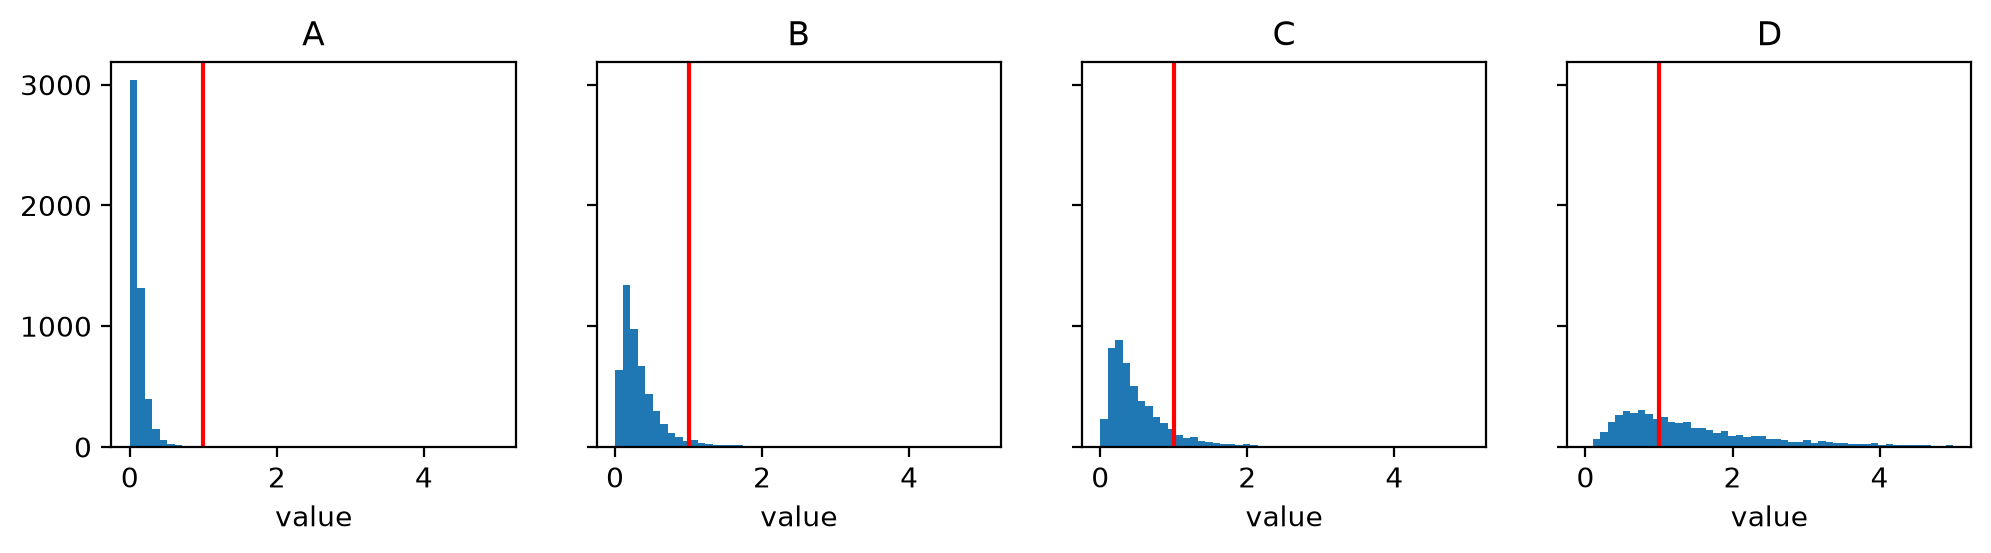

In [ ]:
units = list('ABCD')
mu, spread, level, accepted = np.array([-2.5, -1.4, -0.95, 0.2]), 0.8, 1.0, 0.1
rng = np.random.default_rng(0)
cells = {u: rng.lognormal(m, spread, 5000) for u, m in zip(units, mu)}
fig, axs = plt.subplots(1, 4, figsize=(12, 2.5), sharey=True)
for ax, u in zip(axs, units):
    ax.hist(cells[u], bins=np.linspace(0, 5, 50))
    ax.axvline(level, color='red')
    ax.set(title=u, xlabel='value')

Two numbers describe each unit for what follows: `share`, the share of the unit above the level, and `sd`, the standard deviation of its values. D's values vary most, because they are the largest. C's share is closest to 10%:

In [ ]:
share = norm.sf((np.log(level) - mu) / spread)
sd = np.sqrt(np.exp(spread**2) - 1) * np.exp(mu + spread**2 / 2)
pd.DataFrame({'share': share, 'sd': sd, 'should restrict': share > accepted}, index=units).round(3)

,share,sd,should restrict
A,0.001,0.107,False
B,0.040,0.322,False
C,0.118,0.504,True
D,0.599,1.593,True


## Score 1: the error of each unit's mean

With `n` random samples, the mean of a unit is off by about `sd * sqrt(2 / pi) / sqrt(n)` on average. The score averages that error over the four units, each unit counting the same. It rewards samples where values vary most:

In [ ]:
def mean_error(n): return float((sd * np.sqrt(2 / np.pi) / np.sqrt(np.array(n))).mean())

## Score 2: wrong decisions

With `n` samples, the number above the level is binomial. The unit is restricted when more than 10% of its samples are above the level. The score is the expected number of units whose decision is wrong. It rewards samples where the decision is close:

In [ ]:
def wrong_decisions(n):
    n = np.array(n)
    p_restrict = binom.sf(np.floor(accepted * n), n, share)
    return float(np.where(share > accepted, 1 - p_restrict, p_restrict).sum())

## The best allocation under each score

Try every way of splitting 12 samples over the four units, with at least one each, and keep the best split under each score:

In [ ]:
splits = [s for s in itertools.product(range(1, 10), repeat=4) if sum(s) == 12]
allocs = {'equal': (3, 3, 3, 3), 'best for means': min(splits, key=mean_error), 'best for decisions': min(splits, key=wrong_decisions)}
pd.DataFrame({name: {**dict(zip(units, a)), 'mean error': round(mean_error(a), 3), 'wrong decisions': round(wrong_decisions(a), 2)}
              for name, a in allocs.items()}).T

,A,B,C,D,mean error,wrong decisions
equal,3.0,3.0,3.0,3.0,0.291,0.87
best for means,1.0,2.0,3.0,6.0,0.254,0.77
best for decisions,1.0,1.0,7.0,3.0,0.307,0.52


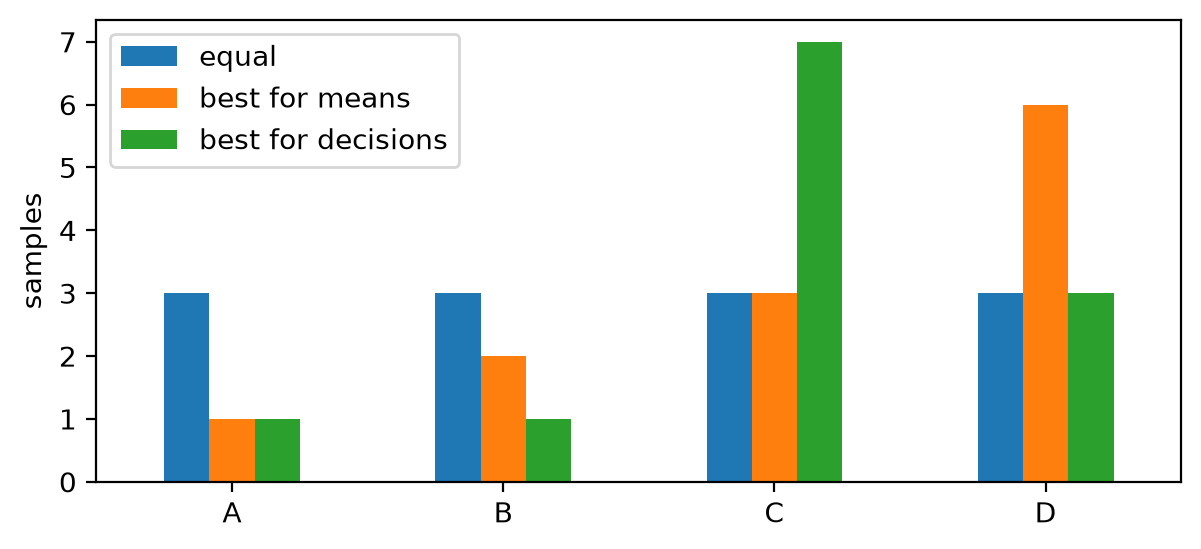

In [ ]:
ax = pd.DataFrame(allocs, index=units).plot.bar(figsize=(7, 3), rot=0)
ax.set(ylabel='samples');

The best split for the means sends 6 of the 12 samples to D, where values vary most. The best split for decisions sends 7 to C, whose share is close to 10%. Each is poor under the other score: the split best for means leaves 0.77 expected wrong decisions against 0.52, and the split best for decisions has a larger mean error than equal allocation.

Equal allocation is a strong choice for the mean error whenever the units vary about as much as each other, which was the case on the simulated rasters. That is why no strategy beat it on the first metrics, and why MCDM looked weak there.

## Which score to use

Decision makers act on decisions, not on means. The DSS4NAFA dashboard turns samples into a restriction decision per unit, so the experiments now score a campaign by comparing its decisions with those the ground truth would give: `decide` and `decisions` in `07_scoring.ipynb`. A wrong decision is either a needless restriction or a missed one. The two may not cost the same, which is still open.

The decision score has its own trap: with the dashboard's rule, one more sample can make a decision less reliable. Notebook 4 explains why.